# Tugas Minggu 4 — Preprocessing & EDA Dataset EMR

**Nama:** Rofiul Khaqim  
**NIM:** 243401009  
**Mata Kuliah:** Data Mining — Praktikum

Mengerjakan tiga bagian tugas pada `Panduan praktikum.pdf`:

| Bagian | Isi | Hasil |
|---|---|---|
| A | 5000 record pertama, seleksi 7 fitur, casefolding, rename, handling missing | 5000 × 8 → **4975 × 7**, 0 missing |
| B | Diskretisasi (`pd.cut`) pada `biaya_berobat` | 12 interval Rp250.000 |
| C | EDA: univariat, 6 analisis multivariat, deteksi outlier IQR | 525 outlier (10,55%) |

**Sumber data:** `IP___Riwayat_Medical_01012016 s.d 19032024 - Copy.xls`, sheet `IP___Riwayat_Medical_200324` — 37.761 record, header asli di baris 4, data mulai baris 5. Contoh keluaran dosen: `dataset.pdf`.

## 0. Persiapan (Google Colab)

1. Panel kiri → ikon folder → **Upload** file `.xls` (14 MB) ke `/content/`.
2. Jalankan sel di bawah untuk memasang pembaca file `.xls` (`xlrd`). Kalau Colab meminta restart runtime, abaikan — lanjut ke sel berikutnya.
3. Notebook ini juga bisa dijalankan lokal: sel pencari file mencoba `/content/`, folder kerja, `MINGGU 4/MATERI/`, lalu `../MATERI/`.

In [1]:
!pip install -q xlrd

## A. Seleksi Fitur, Casefolding, Missing Value

Fitur target sesuai modul: `no`, `diagnosa`, `institusi`, `area`, `rumah`, `tipe`, `biaya_berobat`.
Kolom `Nama Rumah Sakit / Poliklinik (jika Non Langganan)` ikut dibaca sebagai kolom **bantu** untuk mengisi `rumah`, lalu dibuang agar hasil akhir tepat 7 fitur.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

NAMA_FILE = "IP___Riwayat_Medical_01012016 s.d 19032024 - Copy.xls"
KANDIDAT = [
    f"/content/{NAMA_FILE}",               # Colab: file di-upload ke /content
    NAMA_FILE,                             # file di folder kerja
    f"MINGGU 4/MATERI/{NAMA_FILE}",        # dijalankan dari root folder tugas
    f"../MATERI/{NAMA_FILE}",              # dijalankan dari MINGGU 4/TUGAS
]
RAW = next((p for p in KANDIDAT if os.path.exists(p)), None)
assert RAW is not None, "File .xls tidak ditemukan. Upload ke /content/ (Colab) atau simpan di folder ini."
print("Sumber data:", RAW)

Sumber data: ../MATERI/IP___Riwayat_Medical_01012016 s.d 19032024 - Copy.xls


### A.1 Baca 8 kolom yang dipakai (lewati 3 baris judul laporan)

`usecols` memakai huruf kolom Excel: `A`=No, `I`=Diagnosa, `J`=Institusi, `K`=Area Kota, `L`=Rumah Sakit/Poliklinik, `M`=Nama RS non langganan, `N`=Tipe Dokter, `AH`=Total Biaya Penggantian.

In [3]:
raw = pd.read_excel(RAW, engine="xlrd", header=3, usecols="A,I,J,K,L,M,N,AH")
print("shape seluruh data:", raw.shape)
print("kolom:", raw.columns.tolist())
raw.head()

shape seluruh data: (37761, 8)
kolom: ['No', 'Diagnosa Penyakit', 'Institusi', 'Area Kota', 'Rumah Sakit / Poliklinik', 'Nama Rumah Sakit / Poliklinik (jika Non Langganan)', 'Tipe Dokter', 'Total Biaya Penggantian (Rp)']


,No,Diagnosa Penyakit,Institusi,Area Kota,Rumah Sakit / Poliklinik,Nama Rumah Sakit / Poliklinik (jika Non Langganan),Tipe Dokter,Total Biaya Penggantian (Rp)
0,1,hiperkolesterol,Rumah Sakit,Bandung,RS BORROMEUS,NaN,NaN,1172500.0
1,2,Hiperlipidemia,Laboratorium,Garut,NaN,NaN,NaN,454000.0
2,3,Hiperlipidemia,Poliklinik,Garut,KLINIK BHAKTI IP KOSAKA GARUT,NaN,NaN,59000.0
3,4,Vertigo,Poliklinik,Garut,KLINIK BHAKTI IP KOSAKA GARUT,NaN,NaN,80500.0
4,5,Check Up,Laboratorium,Garut,NaN,NaN,NaN,586000.0


### A.2 Ambil 5000 record pertama

Data terurut per karyawan (kolom `Nama`/`NIP`), jadi 5000 baris ini **bukan** sampel acak — lihat catatan di bagian C.1.

In [4]:
df = raw.head(5000).copy()
print("shape 5000 record pertama:", df.shape)
df.head()

shape 5000 record pertama: (5000, 8)


,No,Diagnosa Penyakit,Institusi,Area Kota,Rumah Sakit / Poliklinik,Nama Rumah Sakit / Poliklinik (jika Non Langganan),Tipe Dokter,Total Biaya Penggantian (Rp)
0,1,hiperkolesterol,Rumah Sakit,Bandung,RS BORROMEUS,NaN,NaN,1172500.0
1,2,Hiperlipidemia,Laboratorium,Garut,NaN,NaN,NaN,454000.0
2,3,Hiperlipidemia,Poliklinik,Garut,KLINIK BHAKTI IP KOSAKA GARUT,NaN,NaN,59000.0
3,4,Vertigo,Poliklinik,Garut,KLINIK BHAKTI IP KOSAKA GARUT,NaN,NaN,80500.0
4,5,Check Up,Laboratorium,Garut,NaN,NaN,NaN,586000.0


### A.3 Revisi nama fitur

Nama kolom dibuat lebih umum, huruf kecil, dan spasi diganti underscore (`_`).

In [5]:
df = df.rename(columns={
    "No": "no",
    "Diagnosa Penyakit": "diagnosa",
    "Institusi": "institusi",
    "Area Kota": "area",
    "Rumah Sakit / Poliklinik": "rumah",
    "Nama Rumah Sakit / Poliklinik (jika Non Langganan)": "nama_rumah",
    "Tipe Dokter": "tipe",
    "Total Biaya Penggantian (Rp)": "biaya_berobat",
})
df.columns.tolist()

['no',
 'diagnosa',
 'institusi',
 'area',
 'rumah',
 'nama_rumah',
 'tipe',
 'biaya_berobat']

### A.4 Casefolding

Semua kolom teks dijadikan huruf kecil. Spasi di ujung juga dibuang karena banyak nama faskes ditulis `"Klinik Bunda Alya "` — tanpa `strip()` nama yang sama akan terhitung sebagai dua kategori berbeda.
`no` dijadikan integer (`Int64`) karena dibaca sebagai float.

In [6]:
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip().str.lower()
df["no"] = df["no"].astype("Int64")

print("semua teks lowercase:",
      all(df[c].str.islower().all() for c in df.select_dtypes(include="object").columns))
print("dtype no:", df["no"].dtype)
df.head()

semua teks lowercase: True
dtype no: Int64


,no,diagnosa,institusi,area,rumah,nama_rumah,tipe,biaya_berobat
0,1,hiperkolesterol,rumah sakit,bandung,rs borromeus,NaN,NaN,1172500.0
1,2,hiperlipidemia,laboratorium,garut,NaN,NaN,NaN,454000.0
2,3,hiperlipidemia,poliklinik,garut,klinik bhakti ip kosaka garut,NaN,NaN,59000.0
3,4,vertigo,poliklinik,garut,klinik bhakti ip kosaka garut,NaN,NaN,80500.0
4,5,check up,laboratorium,garut,NaN,NaN,NaN,586000.0


### A.5 Missing value sebelum handling

In [7]:
df.isnull().sum()

no                  0
diagnosa            0
institusi           0
area                0
rumah            1131
nama_rumah       4272
tipe             2750
biaya_berobat      25
dtype: int64

### A.6 Handling missing value

Kebijakan per kolom — satu alasan per keputusan:

1. **`biaya_berobat` (25 kosong)** → baris dibuang. Ini satu-satunya fitur yang akan didiskretisasi; tanpa nilainya baris tidak bisa masuk ke interval mana pun. 25/5000 = 0,5% sehingga aman dibuang.
2. **`rumah` (1131 kosong)** → diisi bertahap dari bukti lain: kolom bantu `nama_rumah` (166 baris), lalu nama `institusi` (961 baris, mis. laboratorium/apotek tanpa nama faskes). Baru setelah dua sumber itu habis, nilai dianggap tidak diketahui — dan ternyata tidak ada.
3. **`tipe` (2750 kosong)** → diisi modus `dokter umum`. Kosong di sini berarti "tidak ada dokter spesialis yang tercatat", bukan data rusak; hasilnya sama dengan contoh di `dataset.pdf` yang memakai `dokter umum`. Modus dihitung setelah `dropna` agar tidak terpengaruh baris yang dibuang.
4. Kolom bantu `nama_rumah` dibuang agar hasil akhir tepat 7 fitur.

In [8]:
# 1) biaya_berobat: satu-satunya fitur yang didiskretisasi -> baris tanpa biaya dibuang
df = df.dropna(subset=["biaya_berobat"])

# 2) rumah: pakai kolom bantu "nama_rumah", lalu fallback ke institusi
df["rumah"] = df["rumah"].fillna(df["nama_rumah"])
df["rumah"] = df["rumah"].fillna(df["institusi"])

# 3) tipe: isi dengan modus (nilai tersering)
df["tipe"] = df["tipe"].fillna(df["tipe"].mode()[0])

df = df.drop(columns=["nama_rumah"])
print("shape setelah handling:", df.shape)
print("total missing:", int(df.isnull().sum().sum()))
df.isnull().sum()

shape setelah handling: (4975, 7)
total missing: 0


no               0
diagnosa         0
institusi        0
area             0
rumah            0
tipe             0
biaya_berobat    0
dtype: int64

**Hasil bagian A**

- 5000 × 8 → **4975 × 7**, total missing **0**.
- `no` tidak lagi berurutan karena 25 nomor hilang bersama baris yang dibuang — sengaja tidak di-reindex agar tiap baris tetap bisa dilacak ke data asli.
- Casefolding menggabungkan kategori yang tadinya beda kapital: `diagnosa` 1523 → **1266** nilai unik, `area` 24 → **22**, `rumah` 69 → 65 sebelum pengisian.
- Pengisian `rumah` dari kolom M menambah nama faskes yang tidak ada di kolom L, sehingga nilai unik `rumah` menjadi **145** (bukan turun) — ini konsekuensi yang wajar dari memakai sumber tambahan.
- Catatan kualitas data: satu sel kolom M berisi angka (`8704000`, baris `no` 1272) sehingga ikut menjadi `NaN` saat casefolding; baris itu punya `rumah = "Non Langganan"` sehingga tidak terpengaruh. Sebanyak **564** baris `rumah` berisi placeholder `non langganan` / `non langganan 100%` / `non langganan 75%` — itu status penjaminan, bukan nama faskes, dan dibiarkan apa adanya karena memang isi aslinya.

## B. Diskretisasi `biaya_berobat`

Biaya bersifat kontinu dan sangat miring (maksimum ratusan juta rupiah), sehingga diubah menjadi interval Rp250.000 seperti contoh `dataset.pdf`. Nilai asli **disimpan dulu** di `biaya_berobat_rp` karena masih dipakai untuk EDA dan deteksi outlier.

In [9]:
# simpan nilai asli sekali saja, supaya sel ini aman dijalankan ulang
if "biaya_berobat_rp" not in df.columns:
    df["biaya_berobat_rp"] = df["biaya_berobat"]

bins = [0, 100_000, 250_001, 500_001, 750_001, 1_000_001, 1_250_001,
        1_500_001, 1_750_001, 2_000_001, 2_250_001, 2_500_001, np.inf]
labels = ["<100.000", "100.000 - 250.000", "250.001 - 500.000",
          "500.001 - 750.000", "750.001 - 1.000.000",
          "1.000.001 - 1.250.000", "1.250.001 - 1.500.000",
          "1.500.001 - 1.750.000", "1.750.001 - 2.000.000",
          "2.000.001 - 2.250.000", "2.250.001 - 2.500.000", ">2.500.000"]

print("semua nilai biaya bilangan bulat:", bool((df["biaya_berobat_rp"] % 1 == 0).all()))
df["biaya_berobat"] = pd.cut(df["biaya_berobat_rp"], bins=bins, labels=labels, right=False)

vc_bin = df["biaya_berobat"].value_counts(sort=False)
print("total record dalam bin:", int(vc_bin.sum()))
vc_bin

semua nilai biaya bilangan bulat: True
total record dalam bin: 4975


biaya_berobat
<100.000                  694
100.000 - 250.000        1720
250.001 - 500.000        1152
500.001 - 750.000         443
750.001 - 1.000.000       288
1.000.001 - 1.250.000     173
1.250.001 - 1.500.000     123
1.500.001 - 1.750.000      64
1.750.001 - 2.000.000      83
2.000.001 - 2.250.000      37
2.250.001 - 2.500.000      16
>2.500.000                182
Name: count, dtype: int64

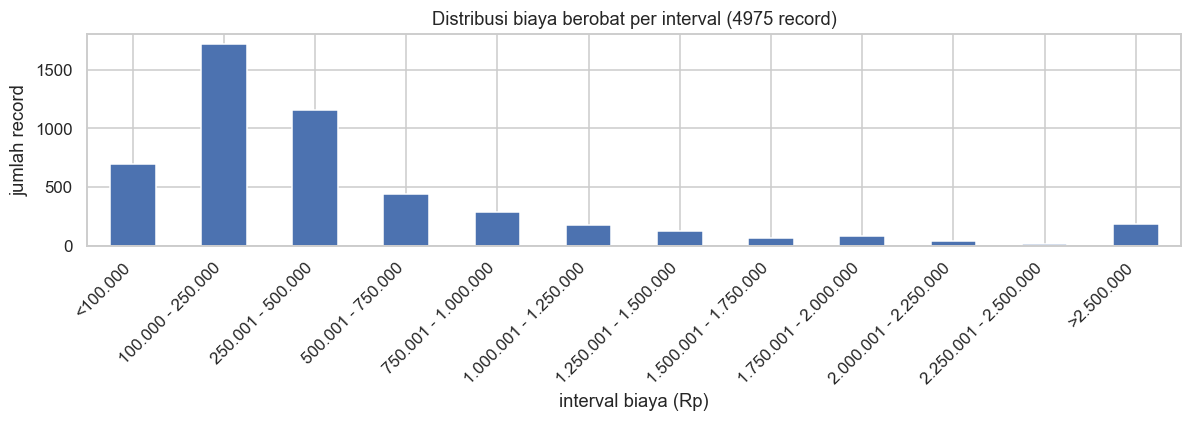

In [10]:
ax = df["biaya_berobat"].value_counts(sort=False).plot(kind="bar", figsize=(11, 4), color="#4C72B0")
ax.set_title("Distribusi biaya berobat per interval (4975 record)")
ax.set_xlabel("interval biaya (Rp)")
ax.set_ylabel("jumlah record")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Kenapa `right=False` dan tepi `…001`**

Label ditulis gaya Indonesia: `100.000` masuk kelompok **`100.000 - 250.000`**, bukan `<100.000`. Supaya perilaku itu konsisten, interval dibuat `[batas_bawah, batas_atas)` dengan `right=False`, dan tepi berikutnya dimulai `250.001` — jadi nilai bulat `250.000` tetap di kelompok bawah, `250.001` masuk kelompok atas. Semua nilai biaya sudah dipastikan bilangan bulat, sehingga tidak ada nilai yang jatuh tepat di antara dua label.

Hasil: 4975 record terbagi ke 12 interval, tanpa `NaN`. Distribusinya sangat tidak seimbang — 48,5% record ≤Rp250.000, sedangkan ekornya (182 record `>2.500.000`) menampung kasus berbiaya besar.

**Catatan perbandingan dengan `dataset.pdf`:** contoh dosen berasal dari ekstraksi/tahap pembersihan yang sedikit berbeda — `diagnosa`-nya lebih ringkas (`kolesterol`, bukan `hiperkolesterol`) dan daftar intervalnya lebih panjang (sampai `3.000.001 - 3.250.000`). Yang disamakan adalah **aturan transformasinya** (lowercase, 7 fitur, interval Rp250.000, `right=False`), bukan string per baris.

## C. EDA — Exploratory Data Analysis

### C.1 Struktur & statistik ringkas

In [11]:
print("shape:", df.shape)
print("\ndtypes:")
print(df.dtypes)
print("catatan: <NA> pada baris `no` muncul karena dtype Int64 (nullable), bukan data hilang")
df.describe(include="all").T

shape: (4975, 8)

dtypes:
no                     Int64
diagnosa              object
institusi             object
area                  object
rumah                 object
tipe                  object
biaya_berobat       category
biaya_berobat_rp     float64
dtype: object
catatan: <NA> pada baris `no` muncul karena dtype Int64 (nullable), bukan data hilang


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
no,4975.0,<NA>,<NA>,<NA>,2495.851658,1442.95982,1.0,1247.5,2491.0,3743.5,5000.0
diagnosa,4975,1266,pemeriksaan,289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
institusi,4975,6,poliklinik,2169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area,4975,22,garut,2709,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rumah,4975,145,klinik bhakti ip kosaka garut,673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipe,4975,24,dokter umum,3533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
biaya_berobat,4975,12,100.000 - 250.000,1720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
biaya_berobat_rp,4975.0,NaN,NaN,NaN,929189.531658,5952576.266899,19000.0,135090.0,261448.0,565792.5,248391800.0


In [12]:
# Catatan sampling: apakah 5000 record pertama mewakili banyak karyawan?
nip = pd.read_excel(RAW, engine="xlrd", header=3, usecols=["NIP"])["NIP"]
print("NIP unik pada 5000 record pertama:", nip.head(5000).nunique())
print("NIP unik pada seluruh file       :", nip.nunique())

NIP unik pada 5000 record pertama: 62
NIP unik pada seluruh file       : 415


**Interpretasi C.1**

- Dataset bersih berukuran **4975 baris × 8 kolom**: 7 fitur target + `biaya_berobat_rp` (nilai asli dalam Rp, hanya dipakai untuk EDA). Dari 7 fitur: `no` integer, `biaya_berobat` kategorik (12 interval), dan 5 fitur teks (`diagnosa`, `institusi`, `area`, `rumah`, `tipe`).
- Kardinalitas sangat tidak seimbang: `institusi` 6 nilai, `area` 22, `tipe` 24, `rumah` 145, dan `diagnosa` **1266 nilai unik (25,4% dari jumlah baris)**. `diagnosa` tidak bisa langsung dipakai sebagai fitur model tanpa pengelompokan/encoding.
- `biaya_berobat` sangat miring ke kanan: rata-rata **Rp929.190** vs median **Rp261.448** (rasio 3,55), maksimum **Rp248.391.800** ≈ 950× median. Rata-rata saja menyesatkan; median dan interval (bagian B) lebih informatif.
- Nilai minimum Rp19.000 dan semua nilai bilangan bulat — tidak ada biaya nol/negatif yang perlu dibersihkan.
- **Keterbatasan sampel:** 5000 record pertama hanya memuat **62 NIP unik**, sedangkan seluruh file berisi 415 NIP. Karena data terurut per karyawan, ini bukan sampel acak: kesimpulan EDA berlaku untuk 62 karyawan tersebut, bukan untuk populasi karyawan.

### C.2 Analisis univariat

**Numerik — `biaya_berobat_rp` (nilai asli)**

In [13]:
df["biaya_berobat_rp"].describe()

count    4.975000e+03
mean     9.291895e+05
std      5.952576e+06
min      1.900000e+04
25%      1.350900e+05
50%      2.614480e+05
75%      5.657925e+05
max      2.483918e+08
Name: biaya_berobat_rp, dtype: float64

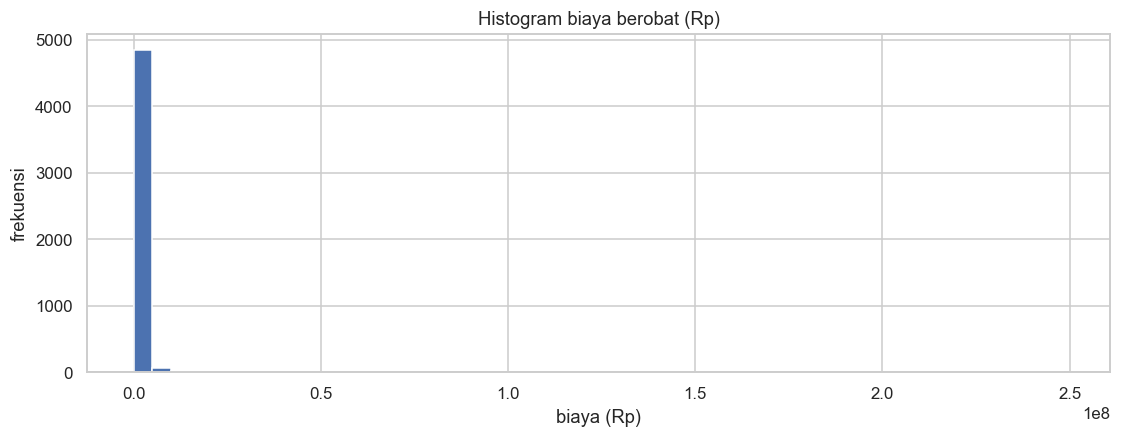

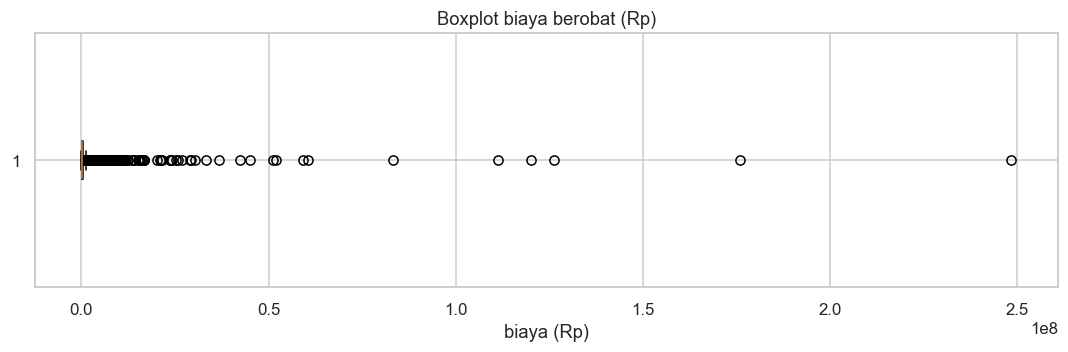

In [14]:
plt.figure(figsize=(12, 4))
plt.hist(df["biaya_berobat_rp"], bins=50)
plt.title("Histogram biaya berobat (Rp)")
plt.xlabel("biaya (Rp)")
plt.ylabel("frekuensi")
plt.show()

plt.figure(figsize=(12, 3))
plt.boxplot(df["biaya_berobat_rp"], vert=False)
plt.title("Boxplot biaya berobat (Rp)")
plt.xlabel("biaya (Rp)")
plt.show()

**Kategorik — tabel frekuensi + diagram batang**

institusi | unique: 6
institusi
poliklinik          2169
rumah sakit         1608
dokter langganan     729
laboratorium         305
apotek               158
puskesmas              6
Name: count, dtype: int64 



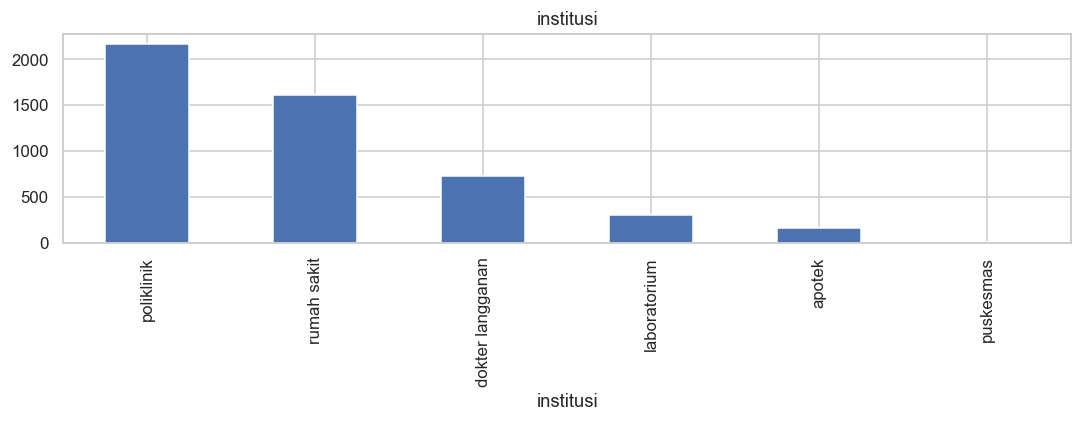

area | unique: 22
area
garut            2709
bandung          1685
sukabumi          440
bekasi             52
semarang           27
jakarta pusat       9
serang              9
pandeglang          6
jakarta timur       6
klaten              6
Name: count, dtype: int64 



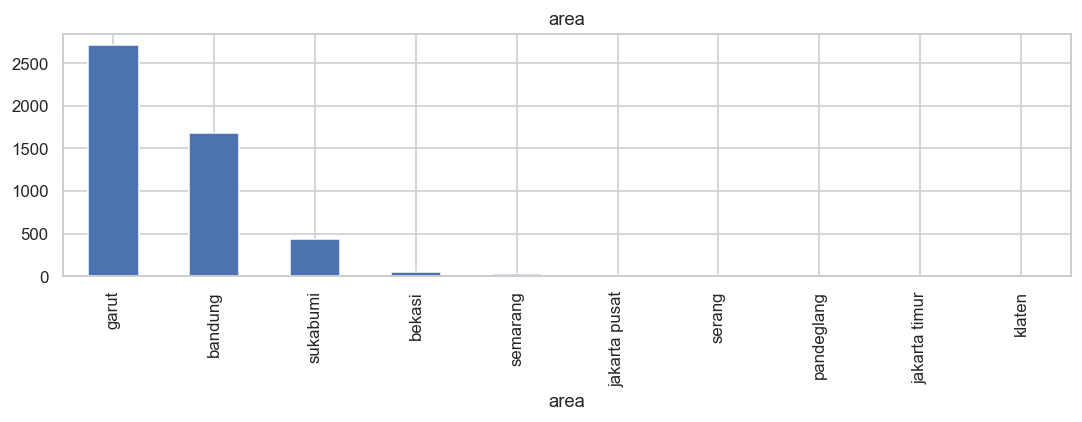

tipe | unique: 24
tipe
dokter umum                    3533
spesialis gigi dan mulut        287
spesialis obsgyn                230
spesialis anak                  218
spesialis penyakit dalam        169
spesialis lain-lain              97
spesialis tht                    89
spesialis mata                   84
spesialis kulit & kelamin        73
spesialis saraf (neurologi)      31
Name: count, dtype: int64 



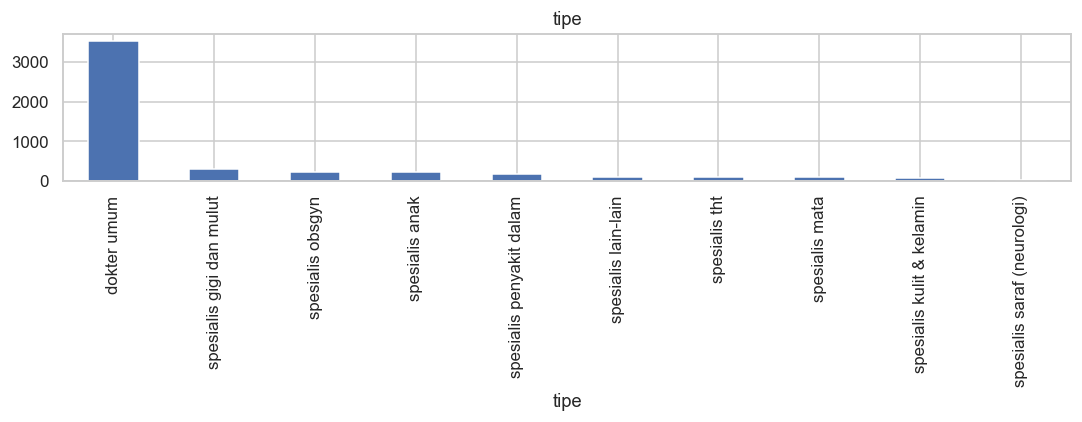

rumah | unique: 145
rumah
klinik bhakti ip kosaka garut             673
rs borromeus                              616
dokter langganan                          537
klinik bhakti ip                          535
klinik pratama sinergi lisna medika 03    388
non langganan 100%                        352
rs intan husada garut                     305
laboratorium                              265
apotek                                    147
non langganan                             129
Name: count, dtype: int64 



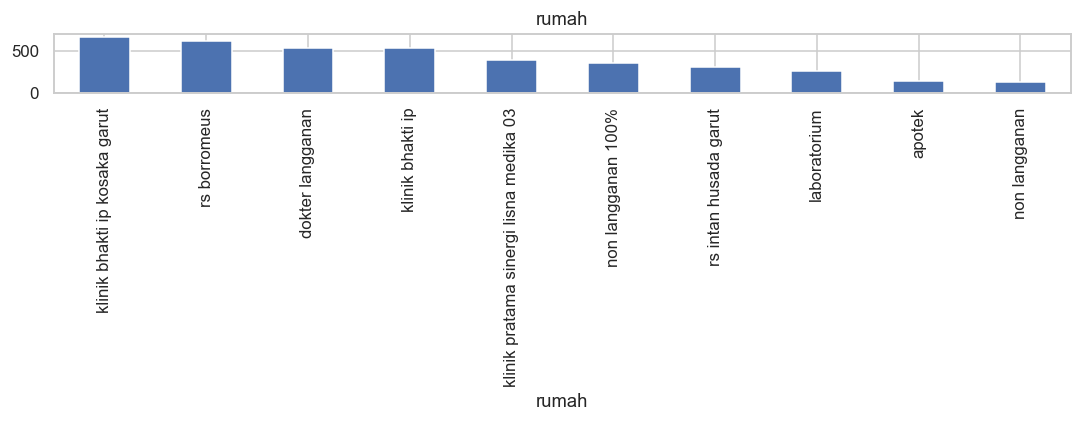

biaya_berobat | unique: 12
biaya_berobat
100.000 - 250.000        1720
250.001 - 500.000        1152
<100.000                  694
500.001 - 750.000         443
750.001 - 1.000.000       288
>2.500.000                182
1.000.001 - 1.250.000     173
1.250.001 - 1.500.000     123
1.750.001 - 2.000.000      83
1.500.001 - 1.750.000      64
Name: count, dtype: int64 



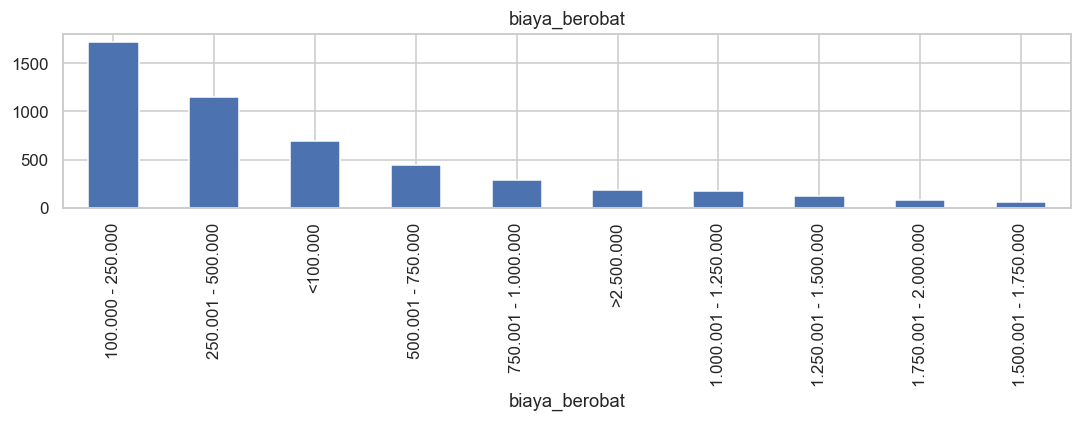

In [15]:
for col in ["institusi", "area", "tipe", "rumah", "biaya_berobat"]:
    vc = df[col].value_counts()
    print(col, "| unique:", len(vc))
    print(vc.head(10), "\n")
    vc.head(10).plot(kind="bar", figsize=(10, 4), title=col)
    plt.tight_layout()
    plt.show()

diagnosa | unique: 1266
diagnosa
pemeriksaan                          289
batuk                                241
gigi                                 178
jantung                              152
demam                                135
ispa                                 134
hipertensi                           121
lambung                              120
flu                                   79
pemeriksaan kandungan - kehamilan     72
Name: count, dtype: int64


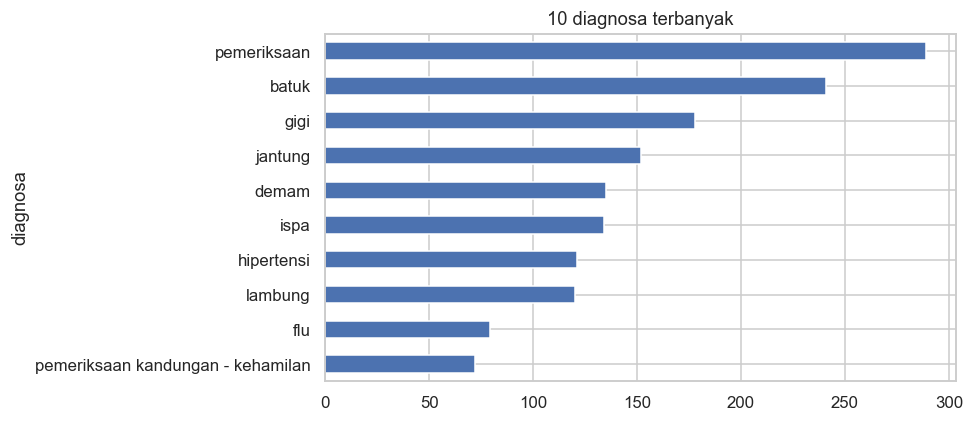

In [16]:
vc = df["diagnosa"].value_counts()
print("diagnosa | unique:", len(vc))
print(vc.head(10))
vc.head(10)[::-1].plot(kind="barh", figsize=(9, 4), title="10 diagnosa terbanyak")
plt.tight_layout()
plt.show()

**Interpretasi C.2**

- **Biaya (nilai asli):** min Rp19.000, Q1 Rp135.090, median Rp261.448, Q3 Rp565.792,5, maks Rp248.391.800. Histogram menumpuk di bawah Rp500.000 dengan ekor panjang ke kanan (*right-skewed*); boxplot memperlihatkan ratusan titik di atas pagar atas. Ini alasan diskretisasi pada bagian B.
- **Institusi:** poliklinik **2169 (43,6%)**, rumah sakit **1608 (32,3%)**, dokter langganan **729 (14,7%)**, laboratorium **305 (6,1%)**, apotek **158 (3,2%)**, puskesmas **6 (0,1%)**. Layanan rawat jalan (poliklinik + dokter langganan) mendominasi.
- **Area:** sangat terkonsentrasi — Garut **2709 (54,4%)** dan Bandung **1685 (33,9%)**, lalu Sukabumi **440 (8,8%)**. Sisanya 17 area masing-masing ≤9 record (≤0,2%). Kalau `area` dipakai untuk model, area berekor ini sebaiknya digabung menjadi `lainnya`.
- **Tipe dokter:** setelah imputasi modus, `dokter umum` **3533 (71,0%)**. Sebelum imputasi hanya **784 (15,8%)**, jadi kenaikan besar ini adalah efek kebijakan missing, bukan temuan klinis — baca sebagai "tidak tercatat spesialis".
- **Diagnosa:** 1266 nilai unik; terbanyak `pemeriksaan` **289 (5,8%)**, `batuk` **241 (4,8%)**, `gigi` **178 (3,6%)**, `jantung` **152 (3,1%)**, `demam` **135 (2,7%)**. Isinya mencampur diagnosis, tindakan, dan status rawat inap (`cek lab` 38 baris, diagnosa yang memuat `ranap` 46 baris, `operasi` 20 baris), sehingga kolom ini lebih tepat diperlakukan sebagai teks bebas.
- **Rumah (faskes):** 145 nilai unik. Tiga teratas `klinik bhakti ip kosaka garut` 673, `rs borromeus` 616, `dokter langganan` 537. Nilai seperti `dokter langganan`, `laboratorium`, `non langganan*` adalah hasil pengisian/placeholder, bukan nama faskes tunggal.

### C.3 Analisis multivariat (6 analisis)

#### C.3.1 Correlation matrix (label encoding)

Modul praktikum memakai `LabelEncoder` + `df.corr()` karena heatmap korelasi hanya menerima angka.

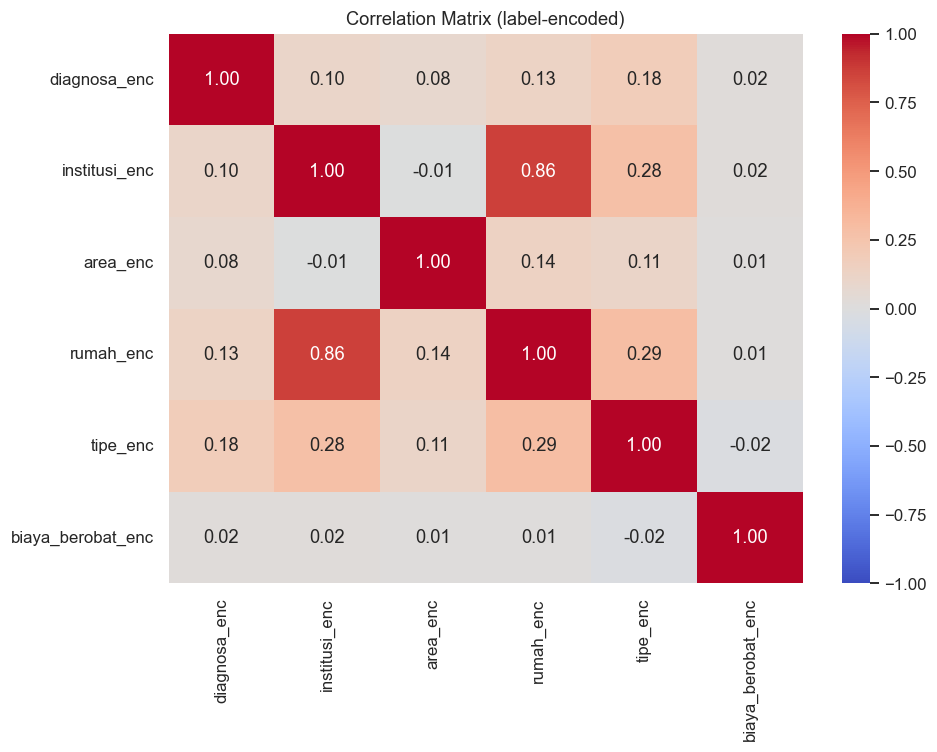

In [17]:
from sklearn.preprocessing import LabelEncoder

enc = df.copy()
for col in ["diagnosa", "institusi", "area", "rumah", "tipe", "biaya_berobat"]:
    enc[col + "_enc"] = LabelEncoder().fit_transform(enc[col])

corr = enc[[c for c in enc.columns if c.endswith("_enc")]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix (label-encoded)")
plt.tight_layout()
plt.show()

**Catatan metode:** `LabelEncoder` memberi urutan semu (alfabetis) pada data nominal, sehingga nilai korelasi di sini **hanya indikatif**, bukan uji statistik. Contoh paling jelas: `biaya_berobat_enc` berkorelasi ≈0 dengan semua fitur (0,02 / 0,01 / −0,02) karena label interval diurutkan alfabetis (`<100.000` → `>2.500.000`), bukan menurut besar biaya — urutan aslinya hilang. Untuk fitur nominal, tabulasi silang (C.3.2–C.3.5) lebih dapat dipercaya.

#### C.3.2 Tabulasi silang institusi × area (5 area teratas)

area              bandung  bekasi  garut  semarang  sukabumi
institusi                                                   
apotek                 23       0    123         0         9
dokter langganan       42       1    619         0        60
laboratorium          103       0    169         1        31
poliklinik            674      13   1411         0        62
puskesmas               1       0      5         0         0
rumah sakit           842      38    382        26       278


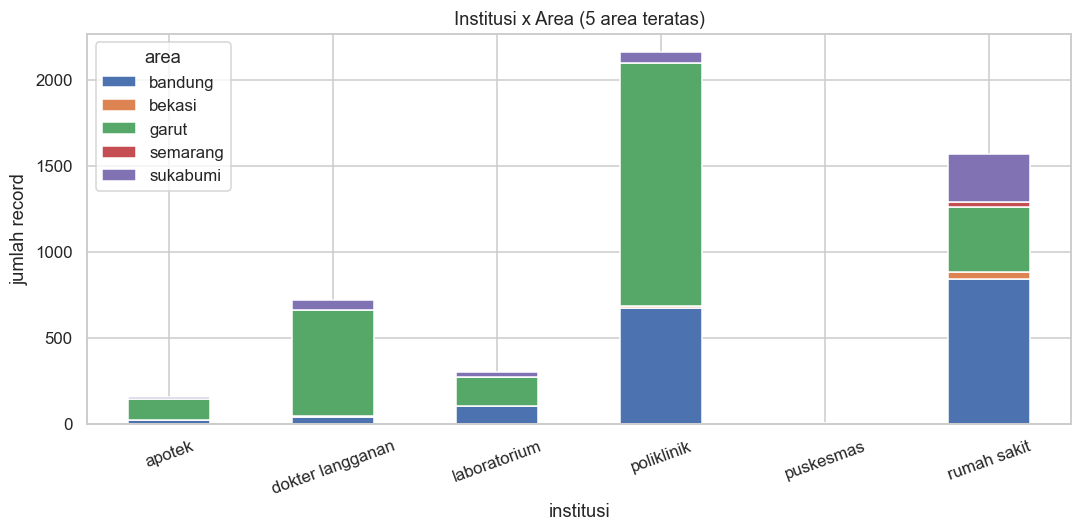

In [18]:
top_area = df["area"].value_counts().head(5).index
sub = df[df["area"].isin(top_area)]
ct = pd.crosstab(sub["institusi"], sub["area"])
print(ct)

ct.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Institusi x Area (5 area teratas)")
plt.ylabel("jumlah record")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### C.3.3 Biaya per institusi

                  count          mean    median
institusi                                      
laboratorium        305  7.715230e+05  675000.0
rumah sakit        1608  2.026156e+06  474218.0
apotek              158  4.577408e+05  284952.0
dokter langganan    729  3.079835e+05  210000.0
poliklinik         2169  3.835410e+05  158200.0
puskesmas             6  1.001667e+05   92500.0


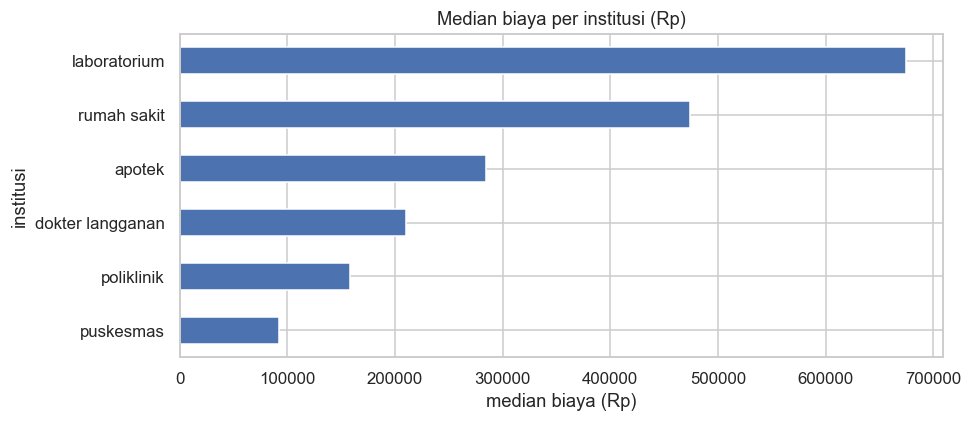

In [19]:
print(df.groupby("institusi")["biaya_berobat_rp"]
        .agg(["count", "mean", "median"]).sort_values("median", ascending=False))

df.groupby("institusi")["biaya_berobat_rp"].median().sort_values().plot(
    kind="barh", figsize=(9, 4), title="Median biaya per institusi (Rp)")
plt.xlabel("median biaya (Rp)")
plt.tight_layout()
plt.show()

#### C.3.4 Tipe dokter × institusi

In [20]:
pd.crosstab(df["tipe"], df["institusi"])

institusi,apotek,dokter langganan,laboratorium,poliklinik,puskesmas,rumah sakit
tipe,,,,,,
dokter umum,141,480,293,1990,5,624
spesialis ahli jiwa,0,0,1,14,0,14
spesialis anak,5,33,1,17,0,162
spesialis bedah,0,0,2,0,0,29
spesialis bedah ortopedi,0,1,0,3,0,16
spesialis bedah saraf,0,0,0,2,0,12
spesialis bedah thorax,0,0,0,0,0,1
spesialis bedah tumor,0,0,0,0,0,1
spesialis bedah umum,0,0,0,0,0,10


#### C.3.5 Diagnosa vs biaya (10 diagnosa terbanyak)

In [21]:
top_diag = df["diagnosa"].value_counts().head(10).index
print(df[df["diagnosa"].isin(top_diag)]
        .groupby("diagnosa")["biaya_berobat_rp"]
        .agg(["count", "median"]).sort_values("median", ascending=False))

                                   count    median
diagnosa                                          
jantung                              152  830553.0
pemeriksaan kandungan - kehamilan     72  452200.0
hipertensi                           121  429000.0
lambung                              120  292600.0
gigi                                 178  245000.0
pemeriksaan                          289  220500.0
demam                                135  217300.0
flu                                   79  166900.0
batuk                                241  161500.0
ispa                                 134  147835.0


#### C.3.6 Sebaran biaya per institusi (skala log)

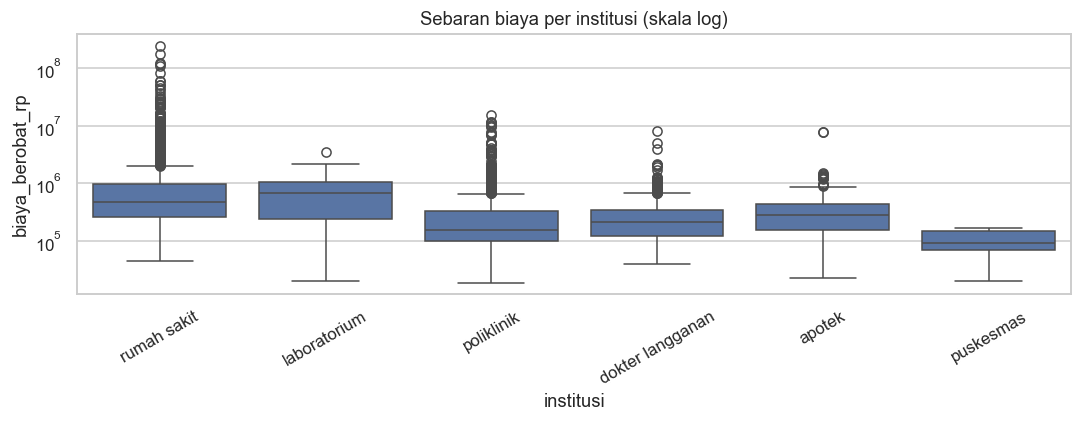

In [22]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="institusi", y="biaya_berobat_rp")
plt.yscale("log")
plt.xticks(rotation=30)
plt.title("Sebaran biaya per institusi (skala log)")
plt.tight_layout()
plt.show()

**Interpretasi C.3 (6 analisis)**

1. **Korelasi (label-encoded):** pasangan terkuat `institusi` ↔ `rumah` = **0,86** — masuk akal karena nama faskes menentukan jenis institusi. `rumah` ↔ `tipe` = 0,29 dan `institusi` ↔ `tipe` = 0,28: tipe dokter terkait jenis layanan. `diagnosa` ↔ `tipe` = 0,18 (paling lemah di antara yang masuk akal). Korelasi `biaya_berobat_enc` ≈ 0 dengan semua fitur **tidak** berarti biaya tidak berhubungan dengan apa pun; urutan alfabetis label interval menghapus informasi besar-biaya. Kesimpulan: matriks ini hanya alat orientasi, bukan uji hipotesis.
2. **Institusi × area:** pola wilayah sangat khas — **Garut** didominasi `poliklinik` 1411 dan `dokter langganan` 619, sedangkan **Bandung** didominasi `rumah sakit` 842 dan poliklinik 674. **Sukabumi** hampir seluruhnya `rumah sakit` 278. Artinya jenis layanan tidak independen dari wilayah: area menentukan institusi mana yang tersedia/terpakai.
3. **Biaya per institusi:** median tertinggi **laboratorium Rp675.000**, lalu **rumah sakit Rp474.218**, apotek Rp284.952, dokter langganan Rp210.000, poliklinik Rp158.200, puskesmas Rp92.500. Menarik: rumah sakit punya rata-rata Rp2.026.156 tetapi median hanya Rp474.218 (rasio ≈4,3) — bukti langsung pengaruh kasus rawat inap berbiaya besar pada rata-rata. Urutan median laboratorium > rumah sakit masuk akal karena laboratorium di data ini menangani paket pemeriksaan, bukan konsultasi murah.
4. **Tipe dokter × institusi:** `dokter umum` mendominasi semua institusi (1990 poliklinik, 624 rumah sakit, 480 dokter langganan, 293 laboratorium, 141 apotek). Spesialis terkonsentrasi di rumah sakit (mis. `spesialis obsgyn` 186 dari 230, `spesialis penyakit dalam` 155 dari 169). Perlu dicatat: 293 baris laboratorium + 141 baris apotek berisi `dokter umum` **karena imputasi modus**, bukan karena ada dokter umum di sana — ini konsekuensi kebijakan missing yang harus disebut.
5. **Diagnosa vs biaya (top-10):** median tertinggi `jantung` **Rp830.553** (152 kasus), lalu `pemeriksaan kandungan - kehamilan` Rp452.200 (72), `hipertensi` Rp429.000 (121); terendah `ispa` **Rp147.835** (134) dan `batuk` Rp161.500 (241). Urutan ini masuk akal secara klinis: penyakit kronis/kehamilan berbiaya lebih besar daripada infeksi saluran napas akut.
6. **Sebaran (log):** rumah sakit punya kotak terlebar dan ekor atas terpanjang (kasus `>2.500.000`), poliklinik paling padat di kisaran rendah, puskesmas paling rendah dan sempit (hanya 6 record) — sebaran biaya tidak homogen antar institusi, jadi perbandingan biaya harus selalu per institusi.

### C.4 Deteksi outlier (IQR)

Memakai fungsi IQR standar (sama seperti modul Part#2): nilai di luar `Q1 − 1,5·IQR` dan `Q3 + 1,5·IQR` dianggap outlier.

In [23]:
def find_outliers_iqr(data):
    Q1 = np.percentile(data, 25)
    Q3 = np.percentile(data, 75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = [x for x in data if x < lower or x > upper]
    return lower, upper, outliers

lower, upper, outliers = find_outliers_iqr(df["biaya_berobat_rp"])
print(f"Q1={np.percentile(df['biaya_berobat_rp'], 25):,.1f}  Q3={np.percentile(df['biaya_berobat_rp'], 75):,.1f}")
print(f"Batas IQR: {lower:,.2f} .. {upper:,.2f}")
print(f"Outlier: {len(outliers)} ({100 * len(outliers) / len(df):.2f}%)")
df.nlargest(10, "biaya_berobat_rp")[["no", "diagnosa", "institusi", "biaya_berobat_rp"]]

Q1=135,090.0  Q3=565,792.5
Batas IQR: -510,963.75 .. 1,211,846.25
Outlier: 525 (10.55%)


,no,diagnosa,institusi,biaya_berobat_rp
359,360,avensi,rumah sakit,248391800.0
914,915,ranap 25feb-25mar2023,rumah sakit,175840927.0
1967,1968,operasi urat kejepit,rumah sakit,126305642.0
731,732,jantung ranap 20-24 apr2022,rumah sakit,120013094.0
1081,1082,diabetes,rumah sakit,111230016.0
1115,1116,ranap 10-18 mar 2022,rumah sakit,83243348.0
4845,4846,ca,rumah sakit,60416693.0
4741,4742,ginjal,rumah sakit,59154058.0
3122,3123,ranap 2-7 jul 2023,rumah sakit,52075765.0
1819,1820,ranap 22 dec 2021 - 7 jan 2022,rumah sakit,51090502.0


**Interpretasi C.4**

- Q1 = **Rp135.090**, Q3 = **Rp565.792,5**, IQR = Rp430.702,5 → batas bawah **−Rp510.963,75** (tidak mungkin tercapai karena biaya ≥ 0) dan batas atas **Rp1.211.846,25**.
- Outlier: **525 record (10,55%)**. Semuanya di ekor kanan; tidak ada outlier bawah.
- 10 nilai terbesar seluruhnya `institusi = rumah sakit`, dengan diagnosa bernuansa rawat inap/tindakan: `ranap 25feb-25mar2023` Rp175.840.927, `operasi urat kejepit` Rp126.305.642, `jantung ranap 20-24 apr2022` Rp120.013.094, hingga maksimum `avensi` **Rp248.391.800** (≈950× median). Ini **bukan data rusak**: biaya besar wajar untuk rawat inap/operasi, dan nilainya konsisten dengan kolom biaya lain di file sumber.
- Tugas bagian C hanya meminta **menemukan** outlier, bukan menghapusnya — dan itu keputusan yang tepat di sini: menghapus 10,55% baris berarti membuang justru kasus berbiaya tinggi yang sah. Diskretisasi bagian B sudah menyerap ekor ini ke interval `>2.500.000` (182 record), sehingga tidak ada tindakan lanjutan yang diperlukan.
- Konsekuensi praktis: model/analisis yang memakai `biaya_berobat_rp` langsung sebaiknya memakai median atau interval, sedangkan `biaya_berobat` versi diskretisasi aman dipakai karena skala ekstrem sudah dipangkas oleh batas atas bin.

## D. Ekspor dataset bersih

In [24]:
final = df[["no", "diagnosa", "institusi", "area", "rumah", "tipe", "biaya_berobat"]].copy()
print("shape final:", final.shape)
print("kolom:", final.columns.tolist())

OUT = "dataset_emr_5000_clean.xlsx"
final.to_excel(OUT, index=False)
print("tersimpan:", OUT)
final.head(3)

try:                                  # hanya ada di Colab
    from google.colab import files
    files.download(OUT)
except ImportError:
    print("Bukan Colab — file tersimpan di folder kerja notebook.")

shape final: (4975, 7)
kolom: ['no', 'diagnosa', 'institusi', 'area', 'rumah', 'tipe', 'biaya_berobat']


tersimpan: dataset_emr_5000_clean.xlsx
Bukan Colab — file tersimpan di folder kerja notebook.


## Kesimpulan

1. **Bagian A** menghasilkan dataset bersih **4975 baris × 7 fitur** dari 5000 record pertama (25 baris dibuang karena `biaya_berobat` kosong). Casefolding + `strip()` menggabungkan kategori yang tadinya beda kapital: `diagnosa` 1523 → 1266 unik, `area` 24 → 22.
2. **Missing value** ditangani dengan bukti berlapis, bukan asal isi: `rumah` dari kolom bantu (166) lalu nama institusi (961), dan `tipe` dari modus `dokter umum` (2749 baris). Total missing akhir 0 dan tidak perlu kategori `tidak diketahui`.
3. **Imputasi `tipe` adalah pilihan yang harus dibaca hati-hati**: `dokter umum` naik dari 784 (15,8%) menjadi 3533 (71,0%) record, dan laboratorium/apotek ikut terisi `dokter umum` padahal secara layanan tidak menangani dokter.
4. **Distribusi layanan terkonsentrasi**: poliklinik 43,6% dan rumah sakit 32,3%; Garut 54,4% dan Bandung 33,9%; 17 area sisanya ≤0,2%. Untuk pemodelan, area yang langka dan diagnosa (1266 unik) perlu pengelompokan kategori.
5. **`biaya_berobat` sangat miring**: rata-rata Rp929.190 vs median Rp261.448, maksimum Rp248.391.800. Rata-rata menyesatkan; median/interval lebih tepat. Diskretisasi menghasilkan 12 interval dengan 48,5% record ≤Rp250.000 dan 182 record `>2.500.000`.
6. **Outlier IQR: 525 record (10,55%)**, batas atas Rp1.211.846,25, semuanya ekor kanan dan terkait rawat inap/operasi di rumah sakit. Tidak dihapus karena sah secara domain; sudah terserap ke bin teratas.
7. **Keterbatasan utama:** 5000 record pertama hanya mencakup **62 dari 415 NIP** dan data terurut per karyawan, sehingga sampel bukan acak. Kesimpulan EDA tidak boleh digeneralisasi ke seluruh populasi karyawan; untuk itu perlu sampling acak 5000 record dari 37.761 record.

## Verifikasi (hasil eksekusi notebook ini)

| Cek | Ekspektasi | Hasil |
|---|---|---|
| shape setelah `head(5000)` | (5000, 8) | ✅ |
| shape setelah handling missing | (4975, 7) | ✅ |
| total missing setelah handling | 0 | ✅ |
| semua teks lowercase / `no` integer | True / `Int64` | ✅ |
| jumlah bin = 4975 | 4975 | ✅ |
| bin terbesar | `100.000 - 250.000` = 1720 | ✅ |
| bin `>2.500.000` | 182 | ✅ |
| outlier IQR | 525 (10,55%), batas atas 1.211.846,25 | ✅ |
| kolom final | `['no', 'diagnosa', 'institusi', 'area', 'rumah', 'tipe', 'biaya_berobat']` | ✅ |
| `dataset_emr_5000_clean.xlsx` | 4975 baris + 1 header, 7 kolom | ✅ |